# Projektauswahl:
## Betrugs-Risiko- und Anomaieerkennung
## Projektidee: 
Es geht darum, ungewöhnliche Transaktionen, Rechnungen zu erkennen und für eine Prüfung zu priorisieren. Die Daten
stammen aus (generate_invoices.py)
# Problemstellung
Unternehmen im Banken-, Versicherungs- und Gesundheitswesen verarbeiten täglich sehr große Mengen an Transaktionen, Rechnungen, Schadensfällen und Kundendaten. Dabei können betrügerische Aktivitäten, Fehler oder ungewöhnliche Auffälligkeiten auftreten, zum Beispiel untypische Zahlungen, doppelte Rechnungen, verdächtige Schadensfälle oder widersprüchliche Patientendaten. Diese Fälle manuell zu prüfen ist zeitaufwendig, teuer und fehleranfällig. Gleichzeitig können nicht erkannte Betrugsfälle oder Risiken hohe finanzielle Verluste, rechtliche Probleme und Reputationsschäden verursachen.

# Definition der Fragestellungen
- Welche Rechnungen oder Tansaktionnen weichen extrem vom normalen Ausgabenmuster ab?
- Wie hoch ist das finanzielle Gesamtrisiko durch identifizierte Betrugsmuster?
- Welche Rechnungen enthalten doppelte Positionen oder Referenznummern?
- Gibt es Lieferanten mit abweichenden oder wechselnden Bankverbindungen?
- Welche Lieferanten oder Dienstleistungskategorien weisen die höchste Anomalie-Quote auf
- Welche Transaktionen müssen von der Revision / Compliance zuerst geprüft werden?
# Leitfaden
- pandas: Daten laden, prüfen, bereinigen
- Python: Tabellen bereinigen und joins ausführen
- Anomalien und Muster erkennen
- KPIs definieren (Betrugsquote, Schadensvolumen, Trefferquote)
- Power BI: Risiko-Dashboard erstellen
- Prüfprioritäten und Handlungsempfehlungen ableiten

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df = pd.read_csv('joined_tabellen_bereinigt.csv')

In [50]:
df.head()

,lieferanten_id,lieferanten_name,stadt,plz,offizielle_iban,median_betrag_eur,streuung,transaktions_id,rechnungsnummer,rechnungsdatum,faelligkeitsdatum,iban,betrag_eur,waehrung,kostenstelle,buchender_mitarbeiter,ist_duplikat_kopie_y,ist_iban_abweichung_y,ist_betrags_ausreisser_y,hat_anomalie
0,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T000063,NaT,2026-01-03,2026-02-02,DE61756828670787846415,566352.0,EUR,KS-015,Beier,0,0,0,0
1,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T000064,NaT,2026-01-03,2026-02-02,DE61756828670787846415,267001.0,EUR,KS-009,Gehringer,0,0,0,0
2,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T000091,NaT,2026-01-04,2026-01-25,DE61756828670787846415,126893.0,EUR,KS-008,Weinhage,0,0,0,0
3,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T000123,NaT,2026-01-05,2026-01-26,DE61756828670787846415,201852.0,EUR,KS-001,Lübs,0,0,0,0
4,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T000161,NaT,2026-01-06,2026-01-27,DE61756828670787846415,319134.0,EUR,KS-022,Hänel,0,0,0,0


In [32]:
df.dtypes

lieferanten_id                  str
lieferanten_name                str
stadt                           str
plz                           int64
offizielle_iban                 str
median_betrag_eur           float64
streuung                    float64
transaktions_id                 str
rechnungsnummer                 str
rechnungsdatum                  str
faelligkeitsdatum               str
iban                            str
betrag_eur                  float64
waehrung                        str
kostenstelle                    str
buchender_mitarbeiter           str
ist_duplikat_kopie_y          int64
ist_iban_abweichung_y         int64
ist_betrags_ausreisser_y      int64
hat_anomalie                  int64
dtype: object

In [33]:
# spalte rechnungsdatum und faelligkeitsdatum in Datum umwandeln
spalten_data_typ = ['rechnungsnummer', 'faelligkeitsdatum']
for col in df.columns:
    if col in spalten_data_typ:
        df[col] = pd.to_datetime(df[col], format='mixed',errors= 'coerce')

In [34]:
df.dtypes


lieferanten_id                         str
lieferanten_name                       str
stadt                                  str
plz                                  int64
offizielle_iban                        str
median_betrag_eur                  float64
streuung                           float64
transaktions_id                        str
rechnungsnummer              datetime64[s]
rechnungsdatum                         str
faelligkeitsdatum           datetime64[us]
iban                                   str
betrag_eur                         float64
waehrung                               str
kostenstelle                           str
buchender_mitarbeiter                  str
ist_duplikat_kopie_y                 int64
ist_iban_abweichung_y                int64
ist_betrags_ausreisser_y             int64
hat_anomalie                         int64
dtype: object

In [35]:
%matplotlib inline

In [39]:
df_anamolie = df[df['hat_anomalie'] == 1]

In [40]:
df_anamolie

,lieferanten_id,lieferanten_name,stadt,plz,offizielle_iban,median_betrag_eur,streuung,transaktions_id,rechnungsnummer,rechnungsdatum,faelligkeitsdatum,iban,betrag_eur,waehrung,kostenstelle,buchender_mitarbeiter,ist_duplikat_kopie_y,ist_iban_abweichung_y,ist_betrags_ausreisser_y,hat_anomalie
56,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T004269,NaT,2026-04-26,2026-05-17,DE61756828670787846415,13435033.0,EUR,KS-012,Atzler,0,0,1,1
69,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T006315,NaT,2026-06-18,2026-07-09,DE86240761016773967220,273877.0,EUR,KS-017,Rosemann,0,1,0,1
96,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T008019,NaT,2026-08-02,2026-08-23,DE61756828670787846415,138875.0,EUR,KS-016,Franke,1,0,0,1
108,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T008710,NaT,2026-08-21,2026-09-20,DE61756828670787846415,128621.0,EUR,KS-011,Täsche,1,0,0,1
112,L001,Dowerg,Unbekannt,33218,DE61756828670787846415,2217.42,1.02,T009172,NaT,2026-09-03,2026-09-17,DE86240761016773967220,139745.0,EUR,KS-009,Hermighausen,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10053,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T005025,NaT,2026-05-14,2026-06-13,DE97332951796406441392,249444.0,EUR,KS-021,Haase,1,0,0,1
10066,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T006044,NaT,2026-06-10,2026-06-24,DE97332951796406441392,161109.0,EUR,KS-021,Hoffmann,1,0,0,1
10068,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T006074,NaT,2026-06-11,2026-06-25,DE97332951796406441392,-50000.0,EUR,KS-009,Carsten,1,0,0,1
10096,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T008112,NaT,2026-08-03,2026-09-02,DE98486818442513634735,365541.0,EUR,KS-018,Wilmsen,0,1,0,1


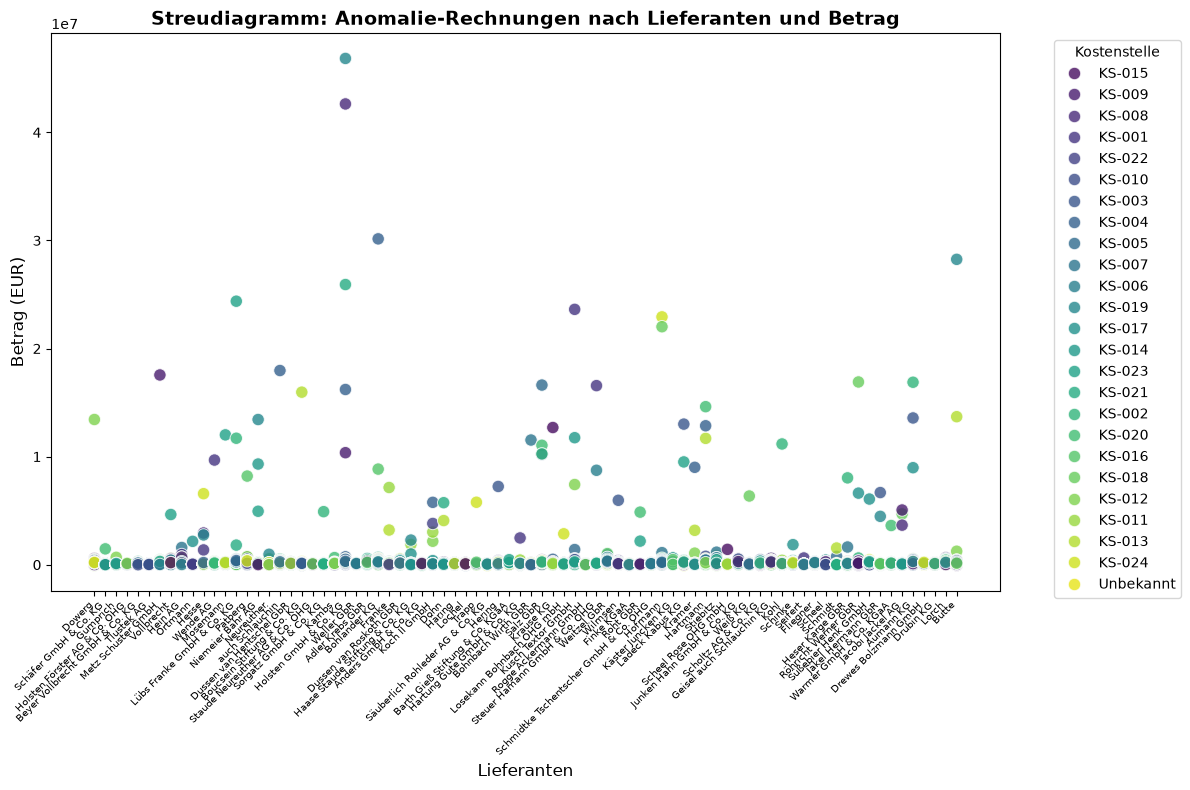

In [41]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df,
    x='lieferanten_name',
    y='betrag_eur',
    hue='kostenstelle',       # Farbliche Unterscheidung nach Kostenstelle
    palette='viridis',
    s=80,
    alpha=0.8
)

# Diagramm-Layout anpassen
plt.title('Streudiagramm: Anomalie-Rechnungen nach Lieferanten und Betrag', fontsize=14, fontweight='bold')
plt.xlabel('Lieferanten', fontsize=12)
plt.ylabel('Betrag (EUR)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.legend(title='Kostenstelle', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

Analyse: Streuungdiagramm Anomalie-Rechnungen.

Das Diagramm zeigt alle Anomalie-Rechnungen nach Lieferant und Betrag. Jeder Punkt ist eine verdächtige Rechnung, eingefärbt nach Kostenstelle.

In [44]:
df.tail()

,lieferanten_id,lieferanten_name,stadt,plz,offizielle_iban,median_betrag_eur,streuung,transaktions_id,rechnungsnummer,rechnungsdatum,faelligkeitsdatum,iban,betrag_eur,waehrung,kostenstelle,buchender_mitarbeiter,ist_duplikat_kopie_y,ist_iban_abweichung_y,ist_betrags_ausreisser_y,hat_anomalie
10115,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T009702,NaT,2026-09-16,2026-10-16,DE97332951796406441392,205362.0,EUR,KS-008,Haase,0,0,0,0
10116,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T009703,NaT,2026-09-16,2026-10-07,DE97332951796406441392,363004.0,EUR,KS-003,Heser,0,0,0,0
10117,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T009932,NaT,2026-09-22,2026-10-22,DE97332951796406441392,246873.0,EUR,KS-019,Hesse,0,0,0,0
10118,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T010052,NaT,2026-09-25,2026-10-25,DE97332951796406441392,203686.0,EUR,KS-003,Hörle,0,0,0,0
10119,L080,Butte,Gerolzhofen,81206,DE97332951796406441392,2436.19,0.84,T010165,NaT,2026-09-28,2026-10-19,DE97332951796406441392,135045.0,EUR,KS-018,Hentschel,0,0,0,0


In [45]:
# Wie hoch ist das finanzielle Gesamtrisiko durch identifizierte Betrugsmuster?
sum_gesamt_betrag = df.loc[:, 'betrag_eur'].notna().sum()
# hat_anomalie
mask_anomalie = df.loc[:, 'hat_anomalie'] == 1
gesamt_sum_anomalie = df.loc[mask_anomalie, 'betrag_eur'].notna().sum()
anomalie_quote = round((gesamt_sum_anomalie / sum_gesamt_betrag),2) * 100
print(anomalie_quote)

4.0


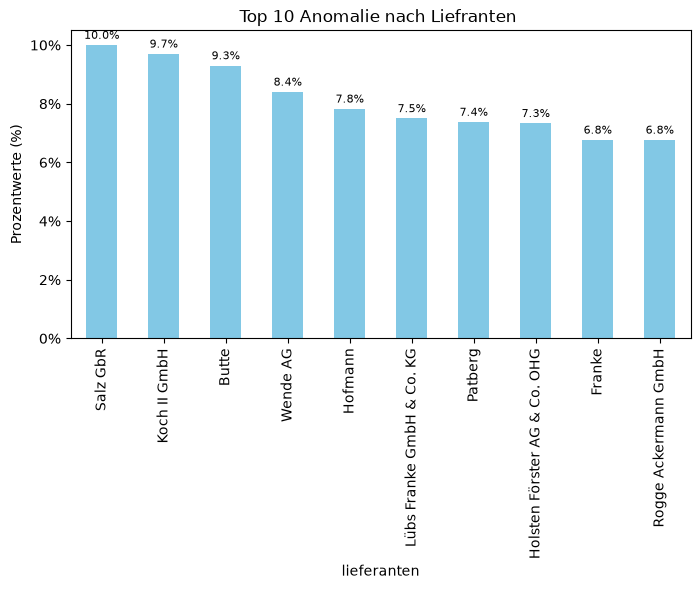

In [48]:
df_top10_iefrante = df.groupby('lieferanten_name')['hat_anomalie'].agg(['mean']).sort_values(by=['mean'], ascending=False)

fig , ax = plt.subplots(figsize=(8,4))
df_top10_iefrante.head(10).plot(kind='bar',
                                ax=ax,
                                title='Top 10 Anomalie nach Liefranten ',
                                color='#82C8E5',
                                legend=False
                                )
ax.set(ylabel= 'Prozentwerte (%)',
      xlabel='lieferanten')
ax.xaxis.set_tick_params(labelrotation=90)
ax.grid(False, axis='y')
ax.grid(False, axis='x')
ax.yaxis.set_major_formatter('{:.0%}'.format)
#Werte auf die Balen setzen
for i, val in enumerate(df_top10_iefrante.head(10)['mean']):
    ax.text(i, val + 0.005, f"{val*100:.1f}%",
            ha='center',
            va='top', 
            fontsize=8
           )


Analyse: Top 10 Anomalie nach Lieferanten.

Dieses Balkendiagramm zeigt die 10 Lieferanten mit den höchsten Anomalie-Quoten — also den prozentualen Anteil auffälliger Rechnungen pro Lieferant.

In [47]:
df_liefr = pd.crosstab(index=df.loc[:,'hat_anomalie'], 
                       columns=df.loc[:,'lieferanten_name'], 
                       normalize='columns')
df_liefr

lieferanten_name,Adler Krebs GbR,Anders GmbH & Co. KG,Aumann KG,Barth Gieß Stiftung & Co. KGaA,Beyer Vollbrecht GmbH & Co. KG,Bohlander KG,Bohnbach Wirth GbR,Boucsein Stiftung & Co. KG,Butte,Dowerg,...,Tlustek AG,Trapp,Vollbrecht,Warmer GmbH & Co. KGaA,Weitzel GbR,Weiß KG,Weller GbR,Wende AG,Wilmsen,auch Schlauchin
hat_anomalie,,,,,,,,,,,,,,,,,,,,,
0,0.96063,0.95935,0.936364,0.952,0.976,0.954545,0.971223,0.96875,0.906977,0.960317,...,0.962617,0.946154,0.945312,0.97561,0.982143,0.961832,0.969231,0.915966,0.965035,0.967742
1,0.03937,0.04065,0.063636,0.048,0.024,0.045455,0.028777,0.03125,0.093023,0.039683,...,0.037383,0.053846,0.054688,0.02439,0.017857,0.038168,0.030769,0.084034,0.034965,0.032258


## Verwendung von Power BI für die weiteren Visualisierungen

### Handlungsempfehlungen:
Aus den Analysen der Rechnungs- und Lieferantendaten sowie den ermittelten KPIs (wie der Betrugsquote von 4,40 % und dem hohen finanziellen Gesamtrisiko) lassen sich konkrete und operative Handlungsempfehlungen für die interne ableiten.
1 - Verstärkte Stammdatenprüfung & IBAN-Kontrolle (Betrugsprävention).
Handlungsempfehlung: Führung eines strikten Vier-Augen-Prinzip bei Änderungen von Bankdaten (IBANs) im ERP-System Beispielweise ein.

2 - Risikobasierte Prüfung von Hochrisiko-Lieferanten (wie z. B. Holstern GmbH oder Salz GbR).
Handlungsempfehlung: Nutzung der  bereinigten Ranglisten und Priorisierungs-Dashboards, um genau diese Lieferanten einer tiefgehenden Rechnungsprüfung zu unterziehen.

3 - Mehrfach vergebene Rechnungsnummern und extreme Betragsausreißer führen zu unnötigen finanziellen Verlusten.
Handlungsempfehlung: Implementierung einer  Systemprüfung im Buchungssystem, die doppelte Rechnungsnummern (ist_duplikat_kopie_y) automatisch blockieren.

4 - Kontinuierliche Überwachung der Daten.
 Power BI Dashboard erstellen um alles zu kontrollieren

 # Ausblick
 - Implementierung einer Echtzeit-Schnittstelle
 - Einsatz von fortgeschrittenem Machine Learning (unsupervised learning)
 - Direkte Verknüpfung des Dashboards mit Prozess-Automatisierungs-Tools ( wie Microsoft Power Automate).